<a href="https://colab.research.google.com/github/Sushmabt680/ADA/blob/main/NLP_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pypdf python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 14.0 MB/s eta 0:00:00


In [2]:
import io, re
import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader
from docx import Document
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from google.colab import files

SKILLS = [
    "python", "java", "c++", "sql", "machine learning", "deep learning",
    "nlp", "git", "docker", "react", "javascript", "pandas", "numpy",
    "tensorflow", "pytorch", "scikit-learn", "flask", "django",
    "aws", "linux", "data analysis", "html", "css",
]

# Weights are assumptions, not ground truth. Change them and compare rankings.
W_SKILLS = 0.6
W_SIMILARITY = 0.4

In [3]:
def extract_text(name, data):
    name = name.lower()
    if name.endswith(".pdf"):
        reader = PdfReader(io.BytesIO(data))
        return "\n".join((p.extract_text() or "") for p in reader.pages)
    if name.endswith(".docx"):
        doc = Document(io.BytesIO(data))
        return "\n".join(p.text for p in doc.paragraphs)
    return data.decode("utf-8", errors="ignore")  # .txt

def anonymize(text):
    """Remove emails and phone numbers (basic bias reduction)."""
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\+?\d[\d\s\-()]{8,}\d", " ", text)
    return text

def clean(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9+#.\s-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def find_skills(text):
    found = set()
    for s in SKILLS:
        pattern = r"(?<![a-z0-9+#])" + re.escape(s) + r"(?![a-z0-9+#])"
        if re.search(pattern, text):
            found.add(s)
    return found

def years_of_experience(text):
    nums = [int(n) for n in re.findall(r"(\d{1,2})\+?\s*years?", text)]
    return max(nums) if nums else 0

In [4]:
job_description = """
We need a Python developer with knowledge of SQL, Machine Learning,
NLP, and Git. Experience with Docker is a plus.
"""
jd_clean = clean(job_description)
required_skills = find_skills(jd_clean)
print("Required skills detected:", sorted(required_skills))

Required skills detected: ['docker', 'git', 'machine learning', 'nlp', 'python', 'sql']


In [12]:
!pip -q install fpdf2

import os
from fpdf import FPDF
from docx import Document

os.makedirs("resumes", exist_ok=True)

resumes = {
"Candidate_A": """Aarav Sharma
Email: aarav.sharma@example.com | Phone: +91 98765 43210

SUMMARY
Data scientist with 3 years of experience building NLP and machine learning solutions.

SKILLS
Python, SQL, Machine Learning, NLP, Git, Docker, Pandas, Scikit-learn

EXPERIENCE
Data Scientist, 3 years
- Built a text classification pipeline using NLP and Python.
- Deployed machine learning models in Docker containers.
- Wrote SQL queries for reporting and used Git for version control.

EDUCATION
B.E. Computer Science

PROJECTS
Resume parser, sentiment analysis tool

CERTIFICATIONS
Machine Learning Specialization""",

"Candidate_B": """Diya Patel
Email: diya.patel@example.com | Phone: +91 91234 56780

SUMMARY
Junior developer with 2 years of experience in analytics and machine learning.

SKILLS
Python, SQL, Machine Learning, Git, Pandas, NumPy

EXPERIENCE
Software Developer, 2 years
- Trained machine learning models for sales prediction using Python.
- Managed code with Git and wrote SQL queries.

EDUCATION
B.Tech Information Technology

PROJECTS
Sales forecasting model""",

"Candidate_C": """Rohan Mehta
Email: rohan.mehta@example.com | Phone: +91 99887 76655

SUMMARY
Front-end developer with 4 years of experience building web applications.

SKILLS
Java, JavaScript, React, HTML, CSS, Git

EXPERIENCE
Web Developer, 4 years
- Built responsive interfaces using React, HTML and CSS.
- Worked with Java back-end services and Git.

EDUCATION
B.Sc Computer Applications

PROJECTS
E-commerce website""",

"Candidate_D": """Sneha Iyer
Email: sneha.iyer@example.com | Phone: +91 90000 11122

SUMMARY
Fresher with strong data analysis skills.

SKILLS
Python, SQL, Data Analysis, Pandas, NumPy

EXPERIENCE
Data Analyst Intern, 1 year
- Cleaned datasets and created dashboards using Python and SQL.

EDUCATION
B.E. Computer Science

PROJECTS
COVID data analysis dashboard""",

"Candidate_E": """Karan Verma
Email: karan.verma@example.com | Phone: +91 97777 88899

SUMMARY
AI engineer with 2 years of experience in language models and deep learning.

SKILLS
Python, NLP, Deep Learning, PyTorch, TensorFlow, Git, Docker, Linux

EXPERIENCE
AI Engineer, 2 years
- Fine-tuned NLP transformer models using PyTorch.
- Containerized services with Docker and managed code in Git.

EDUCATION
M.Tech Artificial Intelligence

PROJECTS
Chatbot using NLP, text summarizer""",
}

# Candidate_A and Candidate_B -> .txt, C and D -> .docx, E -> .pdf
for name, text in resumes.items():
    if name in ("Candidate_A", "Candidate_B"):
        with open(f"resumes/{name}.txt", "w") as f:
            f.write(text)
    elif name in ("Candidate_C", "Candidate_D"):
        doc = Document()
        for line in text.split("\n"):
            doc.add_paragraph(line)
        doc.save(f"resumes/{name}.docx")
    else:
        pdf = FPDF()
        pdf.add_page()
        pdf.set_font("Helvetica", size=11)
        for line in text.split("\n"):
          pdf.multi_cell(0, 6, line, new_x="LMARGIN", new_y="NEXT")
        pdf.output(f"resumes/{name}.pdf")

# Load into the same `uploaded` format that Cell 6 expects
uploaded = {}
for fname in sorted(os.listdir("resumes")):
    with open(os.path.join("resumes", fname), "rb") as f:
        uploaded[fname] = f.read()

print("Loaded resumes:", list(uploaded.keys()))

Loaded resumes: ['Candidate_A.txt', 'Candidate_B.txt', 'Candidate_C.docx', 'Candidate_D.docx', 'Candidate_E.pdf', 'Candidate_E.txt']


In [13]:
rows, texts, names = [], [], []

for fname, data in uploaded.items():
    raw = extract_text(fname, data)
    cleaned = clean(anonymize(raw))
    names.append(fname)
    texts.append(cleaned)

# TF-IDF similarity between each resume and the job description
vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
matrix = vec.fit_transform([jd_clean] + texts)
sims = cosine_similarity(matrix[0:1], matrix[1:]).flatten()

for fname, text, sim in zip(names, texts, sims):
    found = find_skills(text)
    matched = sorted(found & required_skills)
    missing = sorted(required_skills - found)
    skill_score = 100 * len(matched) / len(required_skills) if required_skills else 0
    sim_score = 100 * sim
    final = W_SKILLS * skill_score + W_SIMILARITY * sim_score
    rows.append({
        "Candidate": fname,
        "Skills Score": round(skill_score, 1),
        "Text Similarity": round(sim_score, 1),
        "Final Score": round(final, 1),
        "Matched Skills": ", ".join(matched),
        "Missing Skills": ", ".join(missing),
        "Years Mentioned": years_of_experience(text),
    })

results = pd.DataFrame(rows).sort_values("Final Score", ascending=False)
results.insert(0, "Rank", range(1, len(results) + 1))
results = results.reset_index(drop=True)
display(results)

,Rank,Candidate,Skills Score,Text Similarity,Final Score,Matched Skills,Missing Skills,Years Mentioned
0,1,Candidate_A.txt,100.0,25.9,70.4,"docker, git, machine learning, nlp, python, sql",,3
1,2,Candidate_B.txt,66.7,21.8,48.7,"git, machine learning, python, sql","docker, nlp",2
2,3,Candidate_E.txt,66.7,11.1,44.4,"docker, git, nlp, python","machine learning, sql",2
3,4,Candidate_E.pdf,66.7,10.2,44.1,"docker, git, nlp, python","machine learning, sql",2
4,5,Candidate_D.docx,33.3,4.1,21.6,"python, sql","docker, git, machine learning, nlp",1
5,6,Candidate_C.docx,16.7,6.8,12.7,git,"docker, machine learning, nlp, python, sql",4


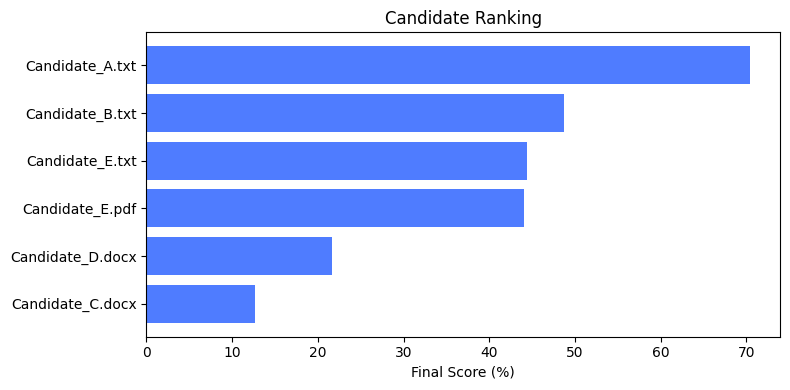

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
plt.figure(figsize=(8, 4))
plt.barh(results["Candidate"][::-1], results["Final Score"][::-1], color="#4f7cff")
plt.xlabel("Final Score (%)")
plt.title("Candidate Ranking")
plt.tight_layout()
plt.savefig("ranking.png", dpi=150)
plt.show()

results.to_csv("ranking_results.csv", index=False)
files.download("ranking_results.csv")

In [15]:
configs = [(0.8, 0.2), (0.6, 0.4), (0.4, 0.6), (0.2, 0.8)]
table = {}
for w_skill, w_sim in configs:
    score = w_skill * results["Skills Score"] + w_sim * results["Text Similarity"]
    order = results.assign(s=score).sort_values("s", ascending=False)["Candidate"].tolist()
    table[f"Skills {int(w_skill*100)} / Sim {int(w_sim*100)}"] = order

sensitivity = pd.DataFrame(table, index=[f"Rank {i}" for i in range(1, len(results) + 1)])
display(sensitivity)

,Skills 80 / Sim 20,Skills 60 / Sim 40,Skills 40 / Sim 60,Skills 20 / Sim 80
Rank 1,Candidate_A.txt,Candidate_A.txt,Candidate_A.txt,Candidate_A.txt
Rank 2,Candidate_B.txt,Candidate_B.txt,Candidate_B.txt,Candidate_B.txt
Rank 3,Candidate_E.txt,Candidate_E.txt,Candidate_E.txt,Candidate_E.txt
Rank 4,Candidate_E.pdf,Candidate_E.pdf,Candidate_E.pdf,Candidate_E.pdf
Rank 5,Candidate_D.docx,Candidate_D.docx,Candidate_D.docx,Candidate_D.docx
Rank 6,Candidate_C.docx,Candidate_C.docx,Candidate_C.docx,Candidate_C.docx


In [16]:
!pip -q install streamlit pypdf python-docx scikit-learn pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 65.2 MB/s eta 0:00:00


In [17]:
%%writefile app.py
import io, re
import pandas as pd
import streamlit as st
from pypdf import PdfReader
from docx import Document
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

st.set_page_config(page_title="AI Resume Screening", layout="wide")

DEFAULT_SKILLS = [
    "python", "java", "c++", "sql", "machine learning", "deep learning",
    "nlp", "git", "docker", "react", "javascript", "pandas", "numpy",
    "tensorflow", "pytorch", "scikit-learn", "flask", "django",
    "aws", "linux", "data analysis", "html", "css",
]

# ---------- helper functions ----------
def extract_text(name, data):
    name = name.lower()
    if name.endswith(".pdf"):
        reader = PdfReader(io.BytesIO(data))
        return "\n".join((p.extract_text() or "") for p in reader.pages)
    if name.endswith(".docx"):
        doc = Document(io.BytesIO(data))
        return "\n".join(p.text for p in doc.paragraphs)
    return data.decode("utf-8", errors="ignore")

def anonymize(text):
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\+?\d[\d\s\-()]{8,}\d", " ", text)
    return text

def clean(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9+#.\s-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def find_skills(text, skills):
    found = set()
    for s in skills:
        pattern = r"(?<![a-z0-9+#])" + re.escape(s) + r"(?![a-z0-9+#])"
        if re.search(pattern, text):
            found.add(s)
    return found

def years_of_experience(text):
    nums = [int(n) for n in re.findall(r"(\d{1,2})\+?\s*years?", text)]
    return max(nums) if nums else 0

# ---------- sidebar ----------
st.sidebar.header("Settings")
w_skills = st.sidebar.slider("Skills match weight (%)", 0, 100, 60, 5)
w_sim = 100 - w_skills
st.sidebar.write(f"Text similarity weight: **{w_sim}%**")
st.sidebar.caption("Weights are adjustable assumptions, not ground truth.")

skills_text = st.sidebar.text_area(
    "Recognized skills (one per line)", "\n".join(DEFAULT_SKILLS), height=300
)
SKILLS = [s.strip().lower() for s in skills_text.splitlines() if s.strip()]

anon = st.sidebar.checkbox("Remove emails & phone numbers before scoring", True)

# ---------- main page ----------
st.title("AI-Based Resume Screening & Candidate Ranking")
st.caption("Decision support only. A recruiter should review resumes and make the final decision.")

col1, col2 = st.columns(2)

with col1:
    st.subheader("1. Job Description")
    jd_file = st.file_uploader("Upload job description (.txt)", type=["txt"], key="jd")
    default_jd = (
        "We need a Python developer with knowledge of SQL, Machine Learning, "
        "NLP, and Git. Experience with Docker is a plus."
    )
    jd_text = st.text_area(
        "...or type / paste it here", value=default_jd, height=180
    )
    if jd_file is not None:
        jd_text = jd_file.read().decode("utf-8", errors="ignore")

with col2:
    st.subheader("2. Resumes")
    resume_files = st.file_uploader(
        "Upload resumes (PDF, DOCX, TXT)",
        type=["pdf", "docx", "txt"],
        accept_multiple_files=True,
    )

if st.button("ANALYZE RESUMES", type="primary"):
    if not resume_files:
        st.warning("Please upload at least one resume.")
        st.stop()

    jd_clean = clean(jd_text)
    required = find_skills(jd_clean, SKILLS)
    if not required:
        st.warning("No recognized skills found in the job description. Edit the skills list or the job description.")
        st.stop()

    names, texts = [], []
    for f in resume_files:
        raw = extract_text(f.name, f.read())
        if anon:
            raw = anonymize(raw)
        names.append(f.name)
        texts.append(clean(raw))

    vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
    matrix = vec.fit_transform([jd_clean] + texts)
    sims = cosine_similarity(matrix[0:1], matrix[1:]).flatten()

    rows = []
    for name, text, sim in zip(names, texts, sims):
        found = find_skills(text, SKILLS)
        matched = sorted(found & required)
        missing = sorted(required - found)
        skill_score = 100 * len(matched) / len(required)
        sim_score = 100 * sim
        final = (w_skills / 100) * skill_score + (w_sim / 100) * sim_score
        rows.append({
            "Candidate": name,
            "Skills Score": round(skill_score, 1),
            "Text Similarity": round(sim_score, 1),
            "Final Score": round(final, 1),
            "Matched Skills": ", ".join(matched) or "-",
            "Missing Skills": ", ".join(missing) or "-",
            "Years Mentioned": years_of_experience(text),
        })

    results = pd.DataFrame(rows).sort_values("Final Score", ascending=False)
    results.insert(0, "Rank", range(1, len(results) + 1))
    results = results.reset_index(drop=True)

    st.session_state["results"] = results
    st.session_state["required"] = sorted(required)

# ---------- results ----------
if "results" in st.session_state:
    results = st.session_state["results"]
    st.divider()
    st.subheader("Required skills detected")
    st.write(", ".join(st.session_state["required"]))

    st.subheader("Candidate Ranking")
    st.dataframe(results, use_container_width=True, hide_index=True)

    st.subheader("Score Comparison")
    chart_df = results.set_index("Candidate")[["Skills Score", "Text Similarity", "Final Score"]]
    st.bar_chart(chart_df)

    st.subheader("Candidate Details")
    for _, r in results.iterrows():
        with st.expander(f"#{r['Rank']}  {r['Candidate']}  -  {r['Final Score']}%"):
            st.write(f"**Matched skills:** {r['Matched Skills']}")
            st.write(f"**Missing skills:** {r['Missing Skills']}")
            st.write(f"**Skills score:** {r['Skills Score']}%  |  **Text similarity:** {r['Text Similarity']}%")

    st.download_button(
        "Download results (CSV)",
        results.to_csv(index=False).encode("utf-8"),
        file_name="ranking_results.csv",
        mime="text/csv",
    )

Writing app.py


In [20]:
import subprocess, time, re, os

# clean up anything already running
!pkill -f streamlit
!pkill -f localtunnel
!pkill -f cloudflared

# download cloudflared (free, no signup)
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

# start Streamlit
subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true",
     "--server.enableCORS", "false", "--server.enableXsrfProtection", "false"],
    stdout=open("streamlit_log.txt", "w"), stderr=subprocess.STDOUT,
)
time.sleep(6)

# start the tunnel and read the public link from its log
subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
    stdout=open("cf_log.txt", "w"), stderr=subprocess.STDOUT,
)

url = None
for _ in range(30):
    time.sleep(2)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("cf_log.txt").read())
    if m:
        url = m.group(0)
        break

print("Open this link:", url if url else "not found, run `!cat cf_log.txt` and paste it here")

Open this link: https://implies-editorials-editions-normally.trycloudflare.com


In [21]:
import os, shutil
from docx import Document
from google.colab import files

os.makedirs("test_files/resumes", exist_ok=True)

# Job description
with open("test_files/job_description.txt", "w") as f:
    f.write("We need a Python developer with knowledge of SQL, Machine Learning, "
            "NLP, and Git. Experience with Docker is a plus.")

resumes = {
"Candidate_A": """Aarav Sharma
SKILLS: Python, SQL, Machine Learning, NLP, Git, Docker, Pandas, Scikit-learn
EXPERIENCE: Data Scientist, 3 years. Built NLP text classification in Python, deployed machine learning models in Docker, wrote SQL queries, used Git.
EDUCATION: B.E. Computer Science""",
"Candidate_B": """Diya Patel
SKILLS: Python, SQL, Machine Learning, Git, Pandas, NumPy
EXPERIENCE: Software Developer, 2 years. Trained machine learning models in Python, used Git and SQL.
EDUCATION: B.Tech Information Technology""",
"Candidate_C": """Rohan Mehta
SKILLS: Java, JavaScript, React, HTML, CSS, Git
EXPERIENCE: Web Developer, 4 years. Built interfaces with React, HTML and CSS, Java back-end, Git.
EDUCATION: B.Sc Computer Applications""",
"Candidate_D": """Sneha Iyer
SKILLS: Python, SQL, Data Analysis, Pandas, NumPy
EXPERIENCE: Data Analyst Intern, 1 year. Cleaned datasets and built dashboards with Python and SQL.
EDUCATION: B.E. Computer Science""",
"Candidate_E": """Karan Verma
SKILLS: Python, NLP, Deep Learning, PyTorch, TensorFlow, Git, Docker, Linux
EXPERIENCE: AI Engineer, 2 years. Fine-tuned NLP transformer models with PyTorch, used Docker and Git.
EDUCATION: M.Tech Artificial Intelligence""",
}

for name, text in resumes.items():
    if name in ("Candidate_A", "Candidate_B", "Candidate_E"):
        with open(f"test_files/resumes/{name}.txt", "w") as f:
            f.write(text)
    else:
        doc = Document()
        for line in text.split("\n"):
            doc.add_paragraph(line)
        doc.save(f"test_files/resumes/{name}.docx")

shutil.make_archive("test_files", "zip", "test_files")
files.download("test_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>